# Electricity theft detection from smart meter data: a practical data mining project

The SGCC dataset holds daily electricity readings for 42,372 customers of the State Grid Corporation of China from 1 January 2014 to 31 October 2016. Each customer is labelled as normal (0) or electricity thief (1). It was released by Zheng et al. (2018), *Wide and Deep Convolutional Neural Networks for Electricity-Theft Detection to Secure Smart Grids*, IEEE Transactions on Industrial Informatics, and is shared at [henryRDlab/ElectricityTheftDetection](https://github.com/henryRDlab/ElectricityTheftDetection).

The notebook acquires the data, cleans and explores it, reduces its dimension with PCA, and then justifies one classification algorithm for finding theft.

## 1. Setup
Libraries are loaded and a fixed seed is set so that every result repeats exactly.

In [1]:
import json, struct, time, zlib, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             make_scorer, confusion_matrix)
import sklearn
SEED = 42
DATA = Path('data/sgcc'); FIG = Path('figures'); RESULTS = 'results_miniproject.json'
DATA.mkdir(parents=True, exist_ok=True); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
NORMAL, THEFT = '#2a6fdb', '#d9472b'
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


## 2. Acquire the data
The CSV is shipped as a split zip in three parts (about 52 MB). Standard unzip tools fail on this split archive, so the single compressed file is read directly from the joined parts and its checksum is checked against the one stored in the archive.

In [2]:
BASE = 'https://raw.githubusercontent.com/henryRDlab/ElectricityTheftDetection/master/'
PARTS = ['data.z01', 'data.z02', 'data.zip']
csv = DATA / 'data.csv'
if not csv.exists():
    for p in PARTS:
        if not (DATA / p).exists():
            urllib.request.urlretrieve(BASE + p, DATA / p)
    b = b''.join((DATA / p).read_bytes() for p in PARTS)[4:]      # skip the split-archive marker
    crc_stored, = struct.unpack('<I', b[14:18]); nl, el = struct.unpack('<HH', b[26:30])
    d, crc, pos = zlib.decompressobj(-15), 0, 30 + nl + el
    with open(csv, 'wb') as f:
        while not d.eof:
            chunk = d.decompress(b[pos:pos + (1 << 20)]); pos += 1 << 20
            f.write(chunk); crc = zlib.crc32(chunk, crc)
    assert crc == crc_stored, 'checksum mismatch'
raw = pd.read_csv(csv)
print(raw.shape, f'{csv.stat().st_size / 1e6:.0f} MB')

(42372, 1036) 175 MB


## 3. First look
The size, labels, date columns, duplicates and value range are checked.

In [3]:
y_all = raw.FLAG.values
X = raw.drop(columns=['CONS_NO', 'FLAG'])
X.columns = pd.to_datetime(X.columns, format='%Y/%m/%d')
print('date columns stored in sorted order?', X.columns.is_monotonic_increasing)
X = X.sort_index(axis=1)
days = pd.date_range(X.columns.min(), X.columns.max())
print('dates missing from the file:', [str(d.date()) for d in days.difference(X.columns)])
X = X.reindex(columns=days)
v = X.values
FIRST = dict(customers=len(X), days=len(days), thieves=int(y_all.sum()), theft_pct=100 * y_all.mean(),
             duplicate_ids=int(raw.CONS_NO.duplicated().sum()),
             repeated_rows=int(X.duplicated().sum()), repeated_with_readings=int((X.duplicated() & (X.fillna(0) != 0).any(axis=1)).sum()), missing_pct=100 * np.isnan(v).mean(),
             negative=int((v < 0).sum()), zero_pct=100 * np.nanmean(v == 0), max_kwh=float(np.nanmax(v)),
             p99_kwh=float(np.nanquantile(v, .99)), all_missing=int(np.isnan(v).all(1).sum()))
for k, val in FIRST.items(): print(f'{k:>14}: {val:,.2f}' if isinstance(val, float) else f'{k:>14}: {val:,}')
print('rows sorted by label (first 3,615 all thieves)?', bool(y_all[:3615].all()))

date columns stored in sorted order? False
dates missing from the file: ['2016-09-18']


     customers: 42,372
          days: 1,035
       thieves: 3,615
     theft_pct: 8.53
 duplicate_ids: 0
 repeated_rows: 878
repeated_with_readings: 2
   missing_pct: 25.71
      negative: 0
      zero_pct: 13.20
       max_kwh: 800,003.32
       p99_kwh: 69.79
   all_missing: 5
rows sorted by label (first 3,615 all thieves)? True


## 4. The missing values tell a story
A quarter of the readings are missing. The share of missing readings is plotted by month for each class. A classifier is then trained on **only the pattern of missing days**, with no consumption at all. If it can find thieves, the missing values carry label information that a model could exploit instead of learning real theft behaviour.

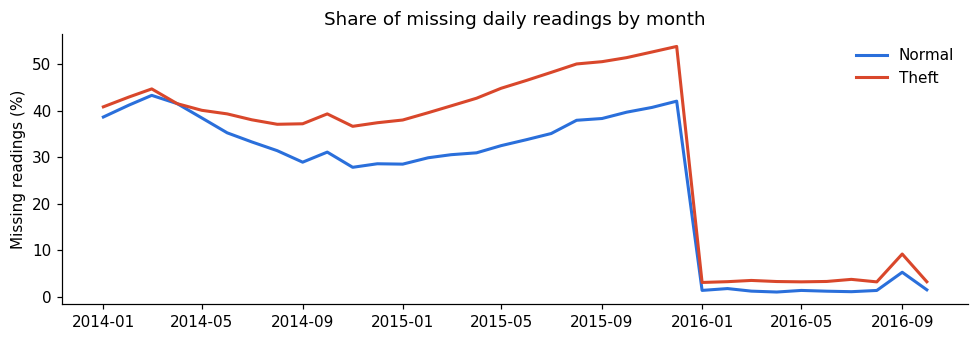

        2014  2015  2016
normal  34.9  35.0   1.8
theft   39.5  46.6   3.9


Missing pattern only, all customers: ROC-AUC 0.851, PR-AUC 0.495


In [4]:
miss = X.isna()
monthly = miss.T.groupby(X.columns.to_period('M')).mean().T
fig, ax = plt.subplots(figsize=(9, 3.2))
for lab, col, name in [(0, NORMAL, 'Normal'), (1, THEFT, 'Theft')]:
    ax.plot(monthly.columns.to_timestamp(), 100 * monthly[y_all == lab].mean(), color=col, lw=2, label=name)
ax.set(ylabel='Missing readings (%)', title='Share of missing daily readings by month'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'missing_by_month.png', bbox_inches='tight'); plt.show()
yr = miss.T.groupby(X.columns.year).mean().T
print((100 * yr.groupby(y_all).mean()).round(1).rename(index={0: 'normal', 1: 'theft'}))

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
n7 = len(days) // 7 * 7
miss_week = miss.values[:, :n7].reshape(len(X), -1, 7).mean(2)
leak = cross_validate(HistGradientBoostingClassifier(random_state=SEED), miss_week, y_all, cv=cv5,
                      scoring=['roc_auc', 'average_precision'])
LEAK = {'all_auc': leak['test_roc_auc'].mean(), 'all_ap': leak['test_average_precision'].mean()}
print(f"Missing pattern only, all customers: ROC-AUC {LEAK['all_auc']:.3f}, PR-AUC {LEAK['all_ap']:.3f}")

## 5. Clean the data
1. **Keep customers with at most 10% missing readings** whose first and last days are both recorded. Every gap then has a real reading on each side, so nothing has to be invented at the ends of a series.
2. **Fill the gaps** by straight-line interpolation between the readings on either side.
3. **Cap outliers** at each customer's own 99th percentile, so their highest 1% of days are lowered to that level. A cap based on the mean and standard deviation was tried first and failed: one huge error inflates both, so readings above 50,000 kWh survived it.
4. **Drop** customers with no consumption at all, and customers whose readings exactly repeat another customer's.
5. **Shuffle the rows.** The file lists all thieves first.

These steps do **not** remove the missing-value leak. The last line below shows that the pattern of missing days still predicts the label among the customers kept, so Section 12 tests how much the final score could depend on it.

In [5]:
MAXMISS = 0.10
pmiss = miss.mean(axis=1).values
ok_miss = pmiss <= MAXMISS
ok_ends = ~miss.values[:, 0] & ~miss.values[:, -1]
keep = ok_miss & ok_ends
filled = X[keep].interpolate(axis=1, limit_area='inside').values
assert not np.isnan(filled).any()
cap = np.quantile(filled, 0.99, axis=1, keepdims=True)
old_mu, old_sd = filled.mean(1, keepdims=True), filled.std(1, keepdims=True)
CAPS = dict(max_before=float(filled.max()), max_mean3sd=float(np.minimum(filled, old_mu + 3 * old_sd).max()),
            max_p99=float(np.minimum(filled, cap).max()), p99_changed_pct=100 * float((filled > cap).mean()))
V = np.minimum(filled, cap)
active = V.sum(1) > 0
repeated = pd.DataFrame(filled).duplicated().values
sel = active & ~repeated
idx = np.where(keep)[0][sel]                                   # row numbers in the original file
order = np.random.default_rng(SEED).permutation(len(idx))     # shuffle once
idx, V = idx[order], V[sel][order]
y, ids, MK = y_all[idx], raw.CONS_NO.values[idx], miss.values[idx]
leak2 = cross_validate(HistGradientBoostingClassifier(random_state=SEED), miss_week[idx], y, cv=cv5,
                       scoring=['roc_auc', 'average_precision'])
LEAK.update(kept_auc=leak2['test_roc_auc'].mean(), kept_ap=leak2['test_average_precision'].mean())
CLEAN = dict(kept_customers=int(len(V)), kept_thieves=int(y.sum()), kept_theft_pct=100 * y.mean(),
             dropped_missing=int((~ok_miss).sum()), dropped_ends=int((ok_miss & ~ok_ends).sum()),
             dropped_zero=int((~active).sum()), dropped_repeated=int((active & repeated).sum()),
             interpolated_pct=100 * MK.mean(), **CAPS)
for k, val in CLEAN.items(): print(f'{k:>18}: {val:,.2f}' if isinstance(val, float) else f'{k:>18}: {val:,}')
print(f"Missing pattern only, kept customers: ROC-AUC {LEAK['kept_auc']:.3f}, PR-AUC {LEAK['kept_ap']:.3f}")

    kept_customers: 18,574
      kept_thieves: 1,222
    kept_theft_pct: 6.58
   dropped_missing: 21,409
      dropped_ends: 1,304
      dropped_zero: 1,085
  dropped_repeated: 0
  interpolated_pct: 2.03
        max_before: 514,991.78
       max_mean3sd: 50,909.65
           max_p99: 7,360.19
   p99_changed_pct: 1.00
Missing pattern only, kept customers: ROC-AUC 0.874, PR-AUC 0.480


## 6. Explore the cleaned data
The typical weekly consumption of each class is compared, then a few behaviour measures.

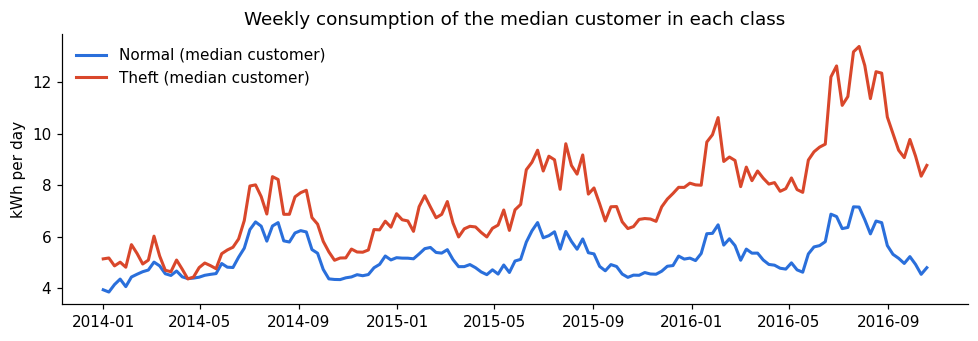

In [6]:
W = V[:, :n7].reshape(len(V), -1, 7).mean(2)          # weekly mean kWh per day
weeks = days[:n7:7]
fig, ax = plt.subplots(figsize=(9, 3.2))
for lab, col, name in [(0, NORMAL, 'Normal'), (1, THEFT, 'Theft')]:
    ax.plot(weeks, np.median(W[y == lab], 0), color=col, lw=2, label=f'{name} (median customer)')
ax.set(ylabel='kWh per day', title='Weekly consumption of the median customer in each class'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'weekly_profile.png', bbox_inches='tight'); plt.show()

## 7. Build features
Each customer's 1,035 daily readings are summarised in two ways.
- **12 behaviour features:** level (mean, median, 10th and 90th percentile, maximum), variability (standard deviation and coefficient of variation), the share of zero days, the long-term trend, the ratio of the last three months to the first three, the number of sudden weekly drops of more than half, and the weekend-to-weekday ratio.
- **147 weekly values** divided by the customer's own mean, giving the *shape* of consumption over time. These are reduced with PCA in the next step.

                 normal   theft
mean_kwh          5.745   8.535
median_kwh        5.000   6.815
p10_kwh           2.010   2.112
p90_kwh          10.112  16.372
max_kwh          16.630  29.963
std_kwh           3.138   6.138
cv                0.562   0.702
zero_share        0.010   0.009
trend             0.045   0.198
last3_vs_first3   1.181   1.842
sudden_drops      3.000   4.000
weekend_ratio     1.015   1.021


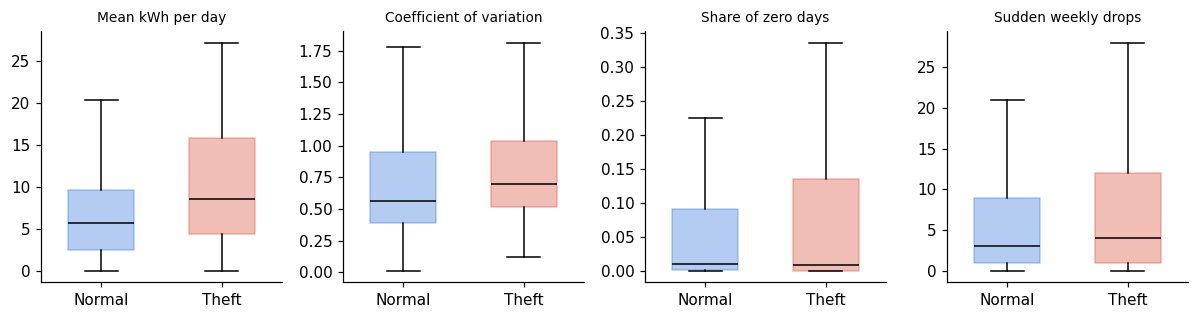

In [7]:
mean = V.mean(1); std = V.std(1); t = np.arange(V.shape[1]); dow = days.day_of_week
F = pd.DataFrame({
    'mean_kwh': mean, 'median_kwh': np.median(V, 1), 'p10_kwh': np.quantile(V, .1, 1), 'p90_kwh': np.quantile(V, .9, 1),
    'max_kwh': V.max(1), 'std_kwh': std, 'cv': std / (mean + 1e-6), 'zero_share': (V == 0).mean(1),
    'trend': np.polyfit(t, V.T, 1)[0] * 365 / (mean + 1e-6),
    'last3_vs_first3': (V[:, -92:].mean(1) + 1e-3) / (V[:, :90].mean(1) + 1e-3),
    'sudden_drops': (np.diff(W, axis=1) < -0.5 * W[:, :-1]).sum(1),
    'weekend_ratio': (V[:, dow >= 5].mean(1) + 1e-3) / (V[:, dow < 5].mean(1) + 1e-3)})
SHAPE = W / (W.mean(1, keepdims=True) + 1e-6)
summ = F.groupby(y).median().T.rename(columns={0: 'normal', 1: 'theft'})
print(summ.round(3))
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for a, col, title in zip(ax, ['mean_kwh', 'cv', 'zero_share', 'sudden_drops'],
                         ['Mean kWh per day', 'Coefficient of variation', 'Share of zero days', 'Sudden weekly drops']):
    data = [F[col][y == 0], F[col][y == 1]]
    lim = np.quantile(F[col], .97)
    bp = a.boxplot([np.clip(d, None, lim) for d in data], tick_labels=['Normal', 'Theft'], showfliers=False, patch_artist=True, widths=.55)
    for patch, c in zip(bp['boxes'], [NORMAL, THEFT]): patch.set(facecolor=c, alpha=.35, edgecolor=c)
    for m in bp['medians']: m.set(color='black')
    a.set_title(title, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'feature_boxplots.png', bbox_inches='tight'); plt.show()

## 8. Dimension reduction with PCA
PCA is fitted on the 147 weekly shape values. The number of components that keeps 90% of the variance is reported. A 2-D plot of the first two components shows how much the classes overlap.

components for 90% of variance: 84 of 147; first 20 keep 57.8%


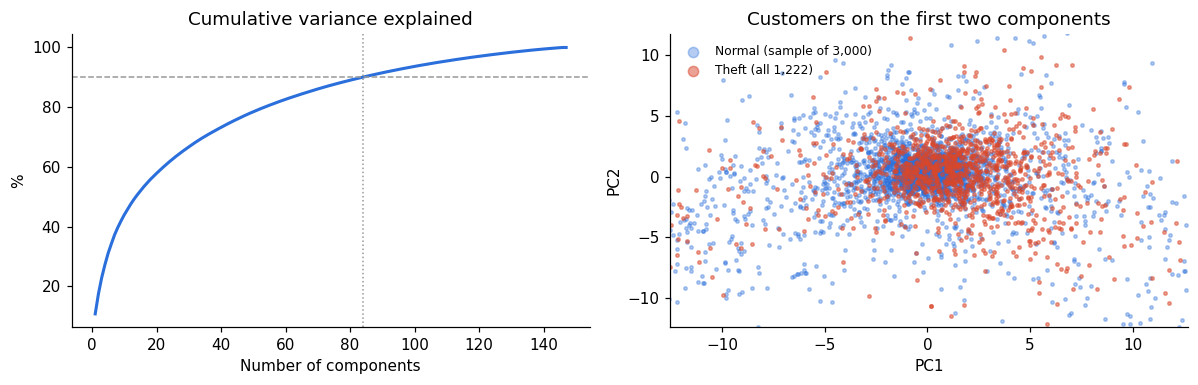

In [8]:
pca_full = PCA(random_state=SEED).fit(StandardScaler().fit_transform(SHAPE))
cum = np.cumsum(pca_full.explained_variance_ratio_)
N90 = int(np.searchsorted(cum, 0.90) + 1); N_PCA = 20
print(f'components for 90% of variance: {N90} of {SHAPE.shape[1]}; first {N_PCA} keep {100 * cum[N_PCA - 1]:.1f}%')
P2 = pca_full.transform(StandardScaler().fit_transform(SHAPE))[:, :2]
rng = np.random.default_rng(SEED); s0 = rng.choice(np.where(y == 0)[0], 3000, replace=False); s1 = np.where(y == 1)[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(1, len(cum) + 1), 100 * cum, color=NORMAL, lw=2); ax[0].axhline(90, color='#999', ls='--', lw=1)
ax[0].axvline(N90, color='#999', ls=':', lw=1); ax[0].set(title='Cumulative variance explained', xlabel='Number of components', ylabel='%')
ax[1].scatter(P2[s0, 0], P2[s0, 1], s=5, alpha=.35, color=NORMAL, label='Normal (sample of 3,000)')
ax[1].scatter(P2[s1, 0], P2[s1, 1], s=5, alpha=.5, color=THEFT, label=f'Theft (all {len(s1):,})')
ax[1].set(title='Customers on the first two components', xlabel='PC1', ylabel='PC2', xlim=np.quantile(P2[:, 0], [.005, .995]), ylim=np.quantile(P2[:, 1], [.005, .995]))
ax[1].legend(frameon=False, fontsize=8, markerscale=3)
plt.tight_layout(); plt.savefig(FIG / 'pca.png', bbox_inches='tight'); plt.show()

## 9. Choose the algorithm
20% of the customers are set aside first as a test set and are not used here. Candidate classifiers are compared on the other 80% with stratified 5-fold cross-validation, on the same features (12 behaviour features plus 20 PCA components). PCA sits inside the pipeline so it is refitted on each training fold.

The metrics suit a rare-class problem:
- **ROC-AUC** measures how well thieves are ranked above normal customers.
- **PR-AUC** (average precision) focuses on the rare theft class.
- **Precision in the top 1% and 5%** is the share of real thieves among the customers an inspection team would visit first.

In [9]:
XF = np.hstack([F.values, SHAPE]); nF = F.shape[1]
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = XF[tr], XF[te], y[tr], y[te]
print(f'training customers {len(tr):,} ({ytr.sum():,} thieves), test customers {len(te):,} ({yte.sum():,} thieves)')
def prep(scale):
    return ColumnTransformer([('feat', StandardScaler() if scale else 'passthrough', list(range(nF))),
                              ('pca', make_pipeline(StandardScaler(), PCA(N_PCA, random_state=SEED)), list(range(nF, XF.shape[1])))])
def top_precision(frac):
    def f(y_true, score):
        k = max(1, int(frac * len(score))); return y_true[np.argsort(-score)[:k]].mean()
    return make_scorer(f, response_method='predict_proba')
SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'prec_top1': top_precision(.01), 'prec_top5': top_precision(.05)}
MODELS = {
    'Baseline (random)': Pipeline([('p', prep(False)), ('m', DummyClassifier(strategy='stratified', random_state=SEED))]),
    'Logistic regression': Pipeline([('p', prep(True)), ('m', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'Random forest': Pipeline([('p', prep(False)), ('m', RandomForestClassifier(400, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
    'Gradient boosting': Pipeline([('p', prep(False)), ('m', HistGradientBoostingClassifier(random_state=SEED))]),
}
rows = {}
for name, model in MODELS.items():
    r = cross_validate(model, Xtr, ytr, cv=cv5, scoring=SCORING)
    rows[name] = {k: r[f'test_{k}'].mean() for k in SCORING} | {'fit_s': r['fit_time'].mean()}
CMP = pd.DataFrame(rows).T; print(CMP.round(3).to_string())

training customers 14,859 (978 thieves), test customers 3,715 (244 thieves)


                     roc_auc  pr_auc  prec_top1  prec_top5  fit_s
Baseline (random)      0.502   0.067      0.069      0.070  0.012
Logistic regression    0.742   0.228      0.490      0.282  0.044
Random forest          0.800   0.314      0.655      0.370  2.047
Gradient boosting      0.790   0.312      0.676      0.381  0.508


## 10. The chosen model on a held-out test set
The random forest is chosen (the reasons are set out in the report and summarised at the end of this notebook). It is trained on the 80% used above and tested on the 20% set aside. Permutation importance shows which features the model relies on.

         roc_auc: 0.792
          pr_auc: 0.293
          test_n: 3715
    test_thieves: 244
  top1_precision: 0.595
     top1_recall: 0.090
          top1_k: 37
  top5_precision: 0.400
     top5_recall: 0.303
          top5_k: 185
 top10_precision: 0.275
    top10_recall: 0.418
         top10_k: 371
confusion matrix when the top 5% are flagged (rows true, cols predicted):
[[3360  111]
 [ 170   74]]


weekly shape (147 values, via PCA)    0.0747
cv                                    0.0194
std_kwh                               0.0165
max_kwh                               0.0152
sudden_drops                          0.0105
p10_kwh                               0.0096
trend                                 0.0095
p90_kwh                               0.0073
zero_share                            0.0057
weekend_ratio                         0.0055
median_kwh                            0.0051
last3_vs_first3                       0.0044
mean_kwh                              0.0017
dtype: float64


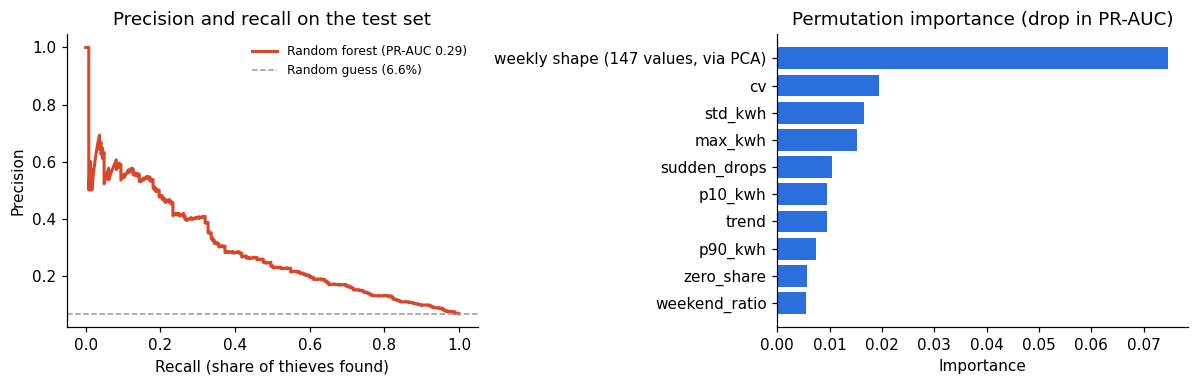

In [10]:
best = MODELS['Random forest'].fit(Xtr, ytr)
p = best.predict_proba(Xte)[:, 1]
TEST = {'roc_auc': roc_auc_score(yte, p), 'pr_auc': average_precision_score(yte, p), 'test_n': int(len(yte)), 'test_thieves': int(yte.sum())}
for frac in [.01, .05, .10]:
    k = int(frac * len(p)); top = np.argsort(-p)[:k]
    TEST[f'top{int(frac * 100)}_precision'] = yte[top].mean(); TEST[f'top{int(frac * 100)}_recall'] = yte[top].sum() / yte.sum()
    TEST[f'top{int(frac * 100)}_k'] = k
for k, val in TEST.items(): print(f'{k:>16}: {val:.3f}' if isinstance(val, float) else f'{k:>16}: {val}')
k5 = TEST['top5_k']; pred = np.zeros_like(yte); pred[np.argsort(-p)[:k5]] = 1
CM = confusion_matrix(yte, pred); print('confusion matrix when the top 5% are flagged (rows true, cols predicted):'); print(CM)

# permutation importance: shuffle one feature (or the whole block of 147 weekly values at once)
# across customers and measure the drop in PR-AUC on the test set
GROUPS = {c: [i] for i, c in enumerate(F.columns)} | {'weekly shape (147 values, via PCA)': list(range(nF, XF.shape[1]))}
base_ap = TEST['pr_auc']; prng = np.random.default_rng(SEED); imp = {}
for g, cols in GROUPS.items():
    drops = []
    for _ in range(5):
        Xp = Xte.copy(); Xp[:, cols] = Xte[prng.permutation(len(Xte))][:, cols]
        drops.append(base_ap - average_precision_score(yte, best.predict_proba(Xp)[:, 1]))
    imp[g] = np.mean(drops)
IMP = pd.Series(imp).sort_values(ascending=False)
print(IMP.round(4))
prec, rec, _ = precision_recall_curve(yte, p)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(rec, prec, color=THEFT, lw=2, label=f"Random forest (PR-AUC {TEST['pr_auc']:.2f})")
ax[0].axhline(yte.mean(), color='#999', ls='--', lw=1, label=f'Random guess ({100 * yte.mean():.1f}%)')
ax[0].set(title='Precision and recall on the test set', xlabel='Recall (share of thieves found)', ylabel='Precision'); ax[0].legend(frameon=False, fontsize=8)
top = IMP.head(10)[::-1]
ax[1].barh(top.index, top.values, color=NORMAL); ax[1].set(title='Permutation importance (drop in PR-AUC)', xlabel='Importance')
plt.tight_layout(); plt.savefig(FIG / 'test_results.png', bbox_inches='tight'); plt.show()

## 11. Does the way gaps are filled matter?
The weekly values are rebuilt by skipping missing days instead of interpolating them. This only shows whether the score depends on the filling method. It does **not** show that the score is free of the leak, because both versions come from the same customers with the same gaps.

In [11]:
import warnings; warnings.filterwarnings('ignore', message='Mean of empty slice')
raw_k = X.values[idx]
W_skip = np.nanmean(np.minimum(raw_k, cap[sel][order])[:, :n7].reshape(len(raw_k), -1, 7), 2)
W_skip = np.where(np.isnan(W_skip), np.nanmean(W_skip, 1, keepdims=True), W_skip)
rf = lambda: RandomForestClassifier(400, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
def score(D, t):
    r = cross_validate(rf(), D, t, cv=cv5, scoring=['roc_auc', 'average_precision'])
    return {'roc_auc': r['test_roc_auc'].mean(), 'pr_auc': r['test_average_precision'].mean()}
CHECK = {'gaps interpolated': score(W, y), 'gaps skipped': score(W_skip, y)}
print(pd.DataFrame(CHECK).T.round(3))

                   roc_auc  pr_auc
gaps interpolated    0.809   0.320
gaps skipped         0.807   0.316


## 12. How much of the score could come from the gaps?
The same test is run on customers with hardly any gaps: no week with more than 3 missing days. A random sample of the same size and theft share from all kept customers is scored too, because a smaller dataset lowers the score by itself. For each group the model is trained on consumption only and then on the missing pattern only.

In [12]:
gap_week = MK[:, :n7].reshape(len(MK), -1, 7)
strict = gap_week.sum(2).max(1) <= 3
Mw = gap_week.mean(2)
n1, n0 = int(y[strict].sum()), int((y[strict] == 0).sum())
STRICT = {'n': int(strict.sum()), 'thieves': n1, 'consumption': score(W[strict], y[strict]), 'missing_pattern': score(Mw[strict], y[strict])}
samp = []
for k in range(5):
    g = np.random.default_rng(SEED + k)
    pick = np.concatenate([g.choice(np.where(y == 1)[0], n1, replace=False), g.choice(np.where(y == 0)[0], n0, replace=False)])
    pick = g.permutation(pick); samp.append(score(W[pick], y[pick]))
STRICT['same_size_random_sample'] = pd.DataFrame(samp).mean().to_dict()
STRICT['all_kept'] = {'n': int(len(y)), 'thieves': int(y.sum()), 'consumption': CHECK['gaps interpolated'], 'missing_pattern': score(Mw, y)}
print(json.dumps(STRICT, indent=1, default=float))

{
 "n": 8206,
 "thieves": 498,
 "consumption": {
  "roc_auc": 0.7803444757555005,
  "pr_auc": 0.24135990176545943
 },
 "missing_pattern": {
  "roc_auc": 0.7936180186425971,
  "pr_auc": 0.2624146725967389
 },
 "same_size_random_sample": {
  "roc_auc": 0.7925860493827444,
  "pr_auc": 0.2782064343712251
 },
 "all_kept": {
  "n": 18574,
  "thieves": 1222,
  "consumption": {
   "roc_auc": 0.8089323601438126,
   "pr_auc": 0.32031040131022803
  },
  "missing_pattern": {
   "roc_auc": 0.8722917663306047,
   "pr_auc": 0.40383301837871144
  }
 }
}


## 13. Save the results
The numbers quoted in the report are written to a JSON file.

In [13]:
out = {'first_look': FIRST, 'leak': LEAK, 'clean': CLEAN, 'pca': {'n90': N90, 'n_used': N_PCA, 'var_used_pct': float(100 * cum[N_PCA - 1]), 'n_inputs': int(SHAPE.shape[1])},
       'class_medians': summ.round(4).to_dict(), 'cv_comparison': CMP.round(4).to_dict('index'), 'test': TEST,
       'confusion_top5': CM.tolist(), 'importance': IMP.round(5).to_dict(), 'gap_check': CHECK, 'strict': STRICT}
Path(RESULTS).write_text(json.dumps(out, indent=2, default=float))
print(json.dumps({'kept': CLEAN['kept_customers'], 'thieves': CLEAN['kept_thieves'], 'test_auc': round(TEST['roc_auc'], 3), 'test_pr_auc': round(TEST['pr_auc'], 3)}))

{"kept": 18574, "thieves": 1222, "test_auc": 0.792, "test_pr_auc": 0.293}
